# Demand forecasting and capacity planning - FRP plant

**The question:** if orders keep coming in at the current rate, which of the three production lines runs out of capacity first - and is it because of people or because of moulds/machines?

The three lines are pressure vessels (hand lay-up on moulds), pultrusion (machines) and moulded grating (moulds).

**Data:** based on real data from an FRP plant, masked. The order book comes from my Order-to-Cash SQL project (`o2c.db`). `Production_Tracker_RAW.xlsx` is rebuilt from the plant's figures - it is the kind of tracker I keep at work, with the same kind of mess. Company, customer and employee names, prices, PO and job numbers are all made up, and the plant figures are changed - so no row is a real record. Every number I measured, looked up or assumed is in `Project2_Data_Collection.xlsx`, tagged so measured and assumed values stay separate.

**How it was made:** the code was written with an AI assistant (Claude). The scope, the data, the masking decisions and the checking are mine - the full split is on the AI disclosure sheet in `Project2_Data_Collection.xlsx`.

Steps:
1. Monthly demand per line from the order book
2. Forecast - compare a few simple methods on past months
3. Clean the production tracker
4. Hours needed vs hours available
5. Mould and machine limits
6. Scenarios
7. Are the standard hours right?
8. Checks, and export for Power BI

In [1]:
import os
import re
import sqlite3
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)

In [2]:
# all the numbers are kept in the data collection workbook so they are easy to change
params = pd.read_excel("Project2_Data_Collection.xlsx", sheet_name="Parameters").dropna(subset=["Value"])
params

,Key,Value,Unit,Type,Source / note
0,hours_per_shift,8.000,hours,PUBLIC,"Factories Act 1948 - 8 hour day, 48 hour week"
1,shifts_per_day,1.000,shifts,ASSUMPTION,One general shift
2,working_days_per_month,25.000,days,PUBLIC,300 working days a year / 12 (DC-MSME project ...
3,effective_time,0.840,fraction,PUBLIC,US Dept of Labor Fact Sheet 39D - allowance at...
4,absence_benchmark,0.110,fraction,PUBLIC,Adhvaryu et al. 2024 - 11% average daily absen...
5,vessel_moulds,5.000,moulds,ASSUMPTION,Indicative - real count not used
6,vessel_crew_per_mould,3.000,people,ASSUMPTION,15 people in the vessel dept / 5 moulds
7,grating_moulds,4.000,moulds,ASSUMPTION,Indicative - real count not used
8,grating_cycle_hours,2.000,hours per panel,PUBLIC,Moulded grating machine listing (Jiubo Composi...
9,grating_panel_m2,4.465,m2,PUBLIC,Standard 3660 x 1220 mm panel


In [3]:
# measured (masked) vs public vs my own assumptions
params["Type"].value_counts()

Type
PUBLIC               7
ASSUMPTION           6
MEASURED (masked)    2
CALCULATED           1
Name: count, dtype: int64

In [4]:
a = dict(zip(params["Key"], params["Value"]))

HOURS_PER_SHIFT = a["hours_per_shift"]
SHIFTS = a["shifts_per_day"]
WORKING_DAYS = a["working_days_per_month"]
EFF = a["effective_time"]

## 1. Monthly demand from the order book

Counting order lines per product line per month. Cancelled orders are taken out, and so is pultruded grating (GR-03) - it is sold under Grating but made on the pultrusion line and isn't in the production tracker.

In [5]:
con = sqlite3.connect("o2c.db")

query = """
SELECT i.product_line               AS line,
       strftime('%Y-%m', o.po_date) AS month,
       COUNT(*)                     AS order_lines
FROM order_lines ol
JOIN items  i ON i.item_id  = ol.item_id
JOIN orders o ON o.order_id = ol.order_id
WHERE o.po_date IS NOT NULL
  AND UPPER(o.order_status) NOT LIKE 'CANCEL%'
  AND ol.item_id <> 'GR-03'
GROUP BY line, month
ORDER BY line, month
"""
demand = pd.read_sql(query, con)
print(demand.shape)
demand.head()

(85, 3)


,line,month,order_lines
0,Grating,2024-04,3
1,Grating,2024-05,2
2,Grating,2024-06,3
3,Grating,2024-07,4
4,Grating,2024-08,2


In [6]:
# months where a line got no orders are missing completely - fill them with 0
months = pd.period_range(demand["month"].min(), demand["month"].max(), freq="M").astype(str)
monthly = demand.pivot(index="month", columns="line", values="order_lines").reindex(months).fillna(0)

print(len(monthly), "months:", months[0], "to", months[-1])
monthly.describe().round(1)

29 months: 2024-04 to 2026-08


line,Grating,Pressure Vessel,Pultrusion
count,29.0,29.0,29.0
mean,2.7,8.9,6.8
std,2.0,3.8,3.2
min,0.0,2.0,0.0
25%,1.0,7.0,5.0
50%,2.0,9.0,7.0
75%,3.0,12.0,8.0
max,8.0,16.0,14.0


### Why order lines and not quantity

I first wanted to forecast quantity, but the quantities in the order book don't make sense for vessels:

In [7]:
qty = pd.read_sql("""
SELECT i.product_line AS line, ol.ordered_qty
FROM order_lines ol
JOIN items i ON i.item_id = ol.item_id
""", con)
con.close()

qty.groupby("line")["ordered_qty"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
line,,,,,,,,
Grating,109.0,82.2,250.2,1.0,3.0,13.0,47.0,2001.0
Pressure Vessel,262.0,148.7,418.4,1.0,3.0,13.5,42.8,2443.0
Pultrusion,202.0,95.6,325.7,1.0,2.0,8.0,29.5,2093.0


A median of 13.5 vessels on one order line, and a maximum of 2,443, is not realistic - a real export PO for vessels is usually single digits. The quantities in my SQL project were generated from one pool for all three lines, so they are not usable here. The **number of order lines** doesn't have this problem, so I forecast order lines and convert them into units later using the tracker.

## 2. Forecast

Only 29 months of data, so I kept it simple and compared four methods:
- **naive** - next month = last month
- **ma3 / ma6** - average of the last 3 or 6 months
- **mean** - average of all months so far

Backtest: start after the first 12 months, predict one month ahead, compare with what actually came in, move one month forward and repeat. Error measure is MAPE. Months with 0 orders are skipped in the MAPE because you can't divide by zero.

I didn't try a seasonal method - with 29 months there are only 2 or 3 of each calendar month, which is too few to trust a seasonal pattern.

In [8]:
def forecast(history, method):
    if method == "naive":
        return history[-1]
    if method == "ma3":
        return np.mean(history[-3:])
    if method == "ma6":
        return np.mean(history[-6:])
    if method == "mean":
        return np.mean(history)


methods = ["naive", "ma3", "ma6", "mean"]
results = []

for line in monthly.columns:
    y = monthly[line].values
    for m in methods:
        errors = []
        for t in range(12, len(y)):
            pred = forecast(y[:t], m)
            actual = y[t]
            if actual > 0:
                errors.append(abs(pred - actual) / actual * 100)
        results.append({"line": line, "method": m,
                        "MAPE": np.mean(errors),
                        "months_tested": len(errors)})

backtest = pd.DataFrame(results)
backtest.pivot(index="method", columns="line", values="MAPE").round(1)

line,Grating,Pressure Vessel,Pultrusion
method,,,
ma3,87.7,57.4,81.7
ma6,69.7,49.7,79.7
mean,55.0,49.7,74.8
naive,112.9,75.1,98.7


In [9]:
best = backtest.loc[backtest.groupby("line")["MAPE"].idxmin()].set_index("line")
best.round(2)

,method,MAPE,months_tested
line,,,
Grating,mean,55.02,17
Pressure Vessel,ma6,49.68,17
Pultrusion,mean,74.80,17


The mean is best for grating and pultrusion. For vessels, ma6 and the mean are basically a tie (49.68 vs 49.74). ma6 is lower by a fraction and it also gives the higher forecast, so I'm going with ma6 - for capacity it is safer to plan a bit high.

The errors are still big (50-75% MAPE). With only about 3 to 9 order lines a month, one order more or less is a big percentage. Naive was the worst on every line, so last month is not a good guide to next month.

In [10]:
forecast_next = pd.Series({line: forecast(monthly[line].values, best.loc[line, "method"])
                           for line in monthly.columns}).round(1)
forecast_next

Grating             2.7
Pressure Vessel    10.5
Pultrusion          6.8
dtype: float64

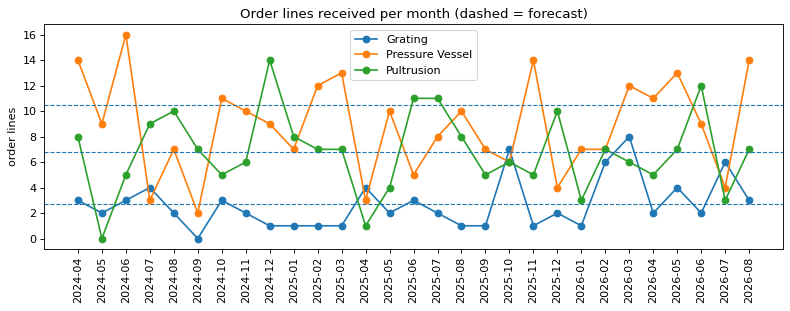

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for line in monthly.columns:
    ax.plot(monthly.index, monthly[line], marker="o", label=line)
    ax.axhline(forecast_next[line], linestyle="--", linewidth=1)
ax.set_title("Order lines received per month (dashed = forecast)")
ax.set_ylabel("order lines")
ax.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("demand.png", dpi=110)
plt.show()

## 3. Clean the production tracker

The tracker has a Daily Production sheet (one row per item per mould/machine per shift), Manpower, Machine Log and a Std Hours sheet. Daily Production is the messy one.

In [12]:
raw = pd.read_excel("Production_Tracker_RAW.xlsx", sheet_name="Daily Production")
print(raw.shape)
raw.head()

(4833, 16)


,Date,Shift,Line,Item,Job No,Line No,Size,Qty,UOM,Machine/Mould,Stage,Operator,Hrs Worked,Downtime Hrs,Downtime Reason,Remarks
0,2025-04-01 00:00:00,A,Grtg,GR-05,10155.0,1.0,38,16,Nos,GM-1,moulding,NaN,8.0,0,NaN,OK
1,01-Apr-25,A,Vessel,PV-1800,10738.0,1.0,1800,NaN,Nos,VM-1,laminating,Ramesh Yadav,8.0,0,NaN,material delay
2,2025-04-01 00:00:00,A,Vessel,PV-1800 (1800 dia vessel),10738.0,1.0,1800,NaN,Nos,VM-2,laminating,Deepak Nair,8.0,0,NaN,NaN
3,2025-04-01 00:00:00,A,pressure vessel,PV-2400,70301.0,1.0,2400,NaN,Nos,VM-3,laminating,Prakash Shinde,8.0,NaN,NaN,balance tomorrow
4,2025-04-01 00:00:00,A,P.V.,PV-2400,70302.0,2.0,2400,NaN,Nos,VM-4,laminating,MJ,8.0,0,NaN,NaN


In [13]:
raw["Line"].value_counts()

Line
Pultrusion         573
PULTRUSION         569
Pult.              561
pultrusion         545
Vessel             323
pressure vessel    320
P.V.               320
PV                 311
Pressure Vessel    304
Grating            243
grating            242
GRATING            236
Grtg               233
TOTAL Apr-25         1
TOTAL May-25         1
TOTAL Jun-25         1
TOTAL Jul-25         1
TOTAL Aug-25         1
TOTAL Sep-25         1
TOTAL Oct-25         1
TOTAL Nov-25         1
TOTAL Dec-25         1
TOTAL Jan-26         1
TOTAL Feb-26         1
TOTAL Mar-26         1
TOTAL Apr-26         1
TOTAL May-26         1
TOTAL Jun-26         1
TOTAL Jul-26         1
TOTAL Aug-26         1
TOTAL Sep-26         1
Name: count, dtype: int64

Problems I can see:
- the same line is typed many different ways (PV, P.V., Vessel, Pult., Grtg...)
- month total rows sitting inside the data, and blank rows between months
- dates in three formats - real dates, `05.08.25` and `05-Aug-25`
- items sometimes written in words ("angle", "1800 dia vessel") instead of the code
- quantity typed with the unit ("12.0 mtr"), so it comes in as text
- a few rows where the quantity went into the Size column

In [14]:
# remove the month total rows and the blank rows
prod = raw[~raw["Line"].astype(str).str.startswith("TOTAL")].copy()
prod = prod.dropna(how="all")
print(len(raw) - len(prod), "rows removed (month totals + blank rows)")

53 rows removed (month totals + blank rows)


In [15]:
line_map = {
    "pressure vessel": "Pressure Vessel", "pv": "Pressure Vessel",
    "p.v.": "Pressure Vessel", "vessel": "Pressure Vessel",
    "pultrusion": "Pultrusion", "pult.": "Pultrusion",
    "grating": "Grating", "grtg": "Grating",
}
prod["Line"] = prod["Line"].str.strip().str.lower().map(line_map)
prod["Line"].value_counts(dropna=False)

Line
Pultrusion         2248
Pressure Vessel    1578
Grating             954
Name: count, dtype: int64

In [16]:
# tried pd.to_datetime(dayfirst=True) on the whole column first, but it read some
# of the 05-Aug-25 type dates wrong without any error, so doing the formats one by one
def fix_date(x):
    if isinstance(x, datetime):
        return pd.Timestamp(x)
    x = str(x).strip()
    for fmt in ("%d.%m.%y", "%d-%b-%y"):
        try:
            return pd.to_datetime(x, format=fmt)
        except ValueError:
            pass
    return pd.NaT


prod["Date"] = prod["Date"].apply(fix_date)
print(prod["Date"].isna().sum(), "dates could not be read")
print(prod["Date"].min().date(), "to", prod["Date"].max().date())

0 dates could not be read
2025-04-01 to 2026-09-30


In [17]:
std = pd.read_excel("Production_Tracker_RAW.xlsx", sheet_name="Std Hours", skiprows=2)
std

,Item,Description,UOM,Std Hrs/Unit,Note
0,PV-1400,1400 dia vessel,Nos,26.00,2 man x 8 hr x ~1.6 day
1,PV-1600,1600 dia vessel,Nos,32.00,NaN
2,PV-1800,1800 dia vessel,Nos,40.00,NaN
3,PV-2000,2000 dia vessel,Nos,48.00,checked on a Jun-25 job
4,PV-2400,2400 dia vessel,Nos,62.00,"looks low, to be revised"
5,PV-2600,2600 dia vessel,Nos,86.00,NaN
6,PV-3000,3000 dia vessel,Nos,118.00,not checked yet
7,PU-01,handrail,Mtr,0.22,machine hrs not man hrs
8,PU-02,angle,Mtr,0.18,NaN
9,PU-03,channel,Mtr,0.24,NaN


In [18]:
# item codes: pull the code out if it is there, otherwise look the words up in the Std Hours list
desc_to_code = dict(zip(std["Description"].str.lower(), std["Item"]))

def fix_item(x):
    x = str(x).strip()
    found = re.search(r"(PV|PU|GR)-\d+", x)
    if found:
        return found.group(0)
    return desc_to_code.get(x.lower())


prod["Item"] = prod["Item"].apply(fix_item)
print(prod["Item"].isna().sum(), "items not matched")
print(prod["Item"].nunique(), "item codes")

0 items not matched
16 item codes


In [19]:
# quantity: strip the unit if someone typed it in
def to_number(x):
    if isinstance(x, (int, float)):
        return x
    x = re.sub(r"[a-zA-Z ]", "", str(x))
    try:
        return float(x)
    except ValueError:
        return np.nan


prod["Qty"] = prod["Qty"].apply(to_number)
prod["Size"] = prod["Size"].apply(to_number)

In [20]:
# laminating and curing rows are a vessel sitting on the mould - qty is only filled
# on the day it comes off, so a blank qty there is correct, not missing
output_stages = ["pulling", "moulding", "demould and finish"]
prod["is_output"] = prod["Stage"].isin(output_stages)

# a few rows have the qty in the Size column. real sizes are vessel diameters or
# grating depths, so anything else in Size on an output row with no qty is the qty
real_sizes = [1400, 1600, 1800, 2000, 2400, 2600, 3000, 25, 30, 38, 40, 50]
moved = prod["is_output"] & prod["Qty"].isna() & prod["Size"].notna() & ~prod["Size"].isin(real_sizes)
print(moved.sum(), "rows with qty in the Size column - moved back")
prod.loc[moved, "Qty"] = prod.loc[moved, "Size"]

bad = prod["is_output"] & prod["Qty"].isna()
print(bad.sum(), "output row(s) with no usable qty - dropped")
prod[bad]

11 rows with qty in the Size column - moved back
1 output row(s) with no usable qty - dropped


,Date,Shift,Line,Item,Job No,Line No,Size,Qty,UOM,Machine/Mould,Stage,Operator,Hrs Worked,Downtime Hrs,Downtime Reason,Remarks,is_output
2591,2026-02-02,A,Pultrusion,PU-01,10908.0,1.0,NaN,NaN,Mtr,M1,pulling,Pankaj Mehta,6.5,1.5,power failure,mould no. changed mid shift,True


In [21]:
prod = prod[~bad]
out = prod[prod["is_output"]].copy()
out["month"] = out["Date"].dt.to_period("M").astype(str)
print(len(prod), "rows after cleaning,", len(out), "of them output rows")

4779 rows after cleaning, 3439 of them output rows


## 4. Hours needed vs hours available

**Units.** Each line should be in one unit: vessels in Nos, pultrusion in metres, grating in m2. Two items are counted in Nos - ladder stringers (one stringer = one 2.4 m plank) and stair treads (cut from a quarter panel) - so I convert those.

**Standard hours.** The Std Hours sheet is a thumb rule, not a time study. Its own notes say vessels and grating are man-hours ("2 man x 8 hr"), but pultrusion is machine hours ("machine hrs not man hrs"). So pultrusion has to be multiplied by the people per machine: 10 people on 6 machines = 1.67.

In [22]:
out["units"] = out["Qty"]
out.loc[out["Item"] == "PU-05", "units"] = out["Qty"] * a["pultrusion_plank_m"]
out.loc[out["Item"] == "GR-05", "units"] = out["Qty"] * a["stair_tread_m2"]

std_hrs = dict(zip(std["Item"], std["Std Hrs/Unit"]))
PULT_CREW = a["pultrusion_people"] / a["pultrusion_machines"]

out["std_hours"] = out["Qty"] * out["Item"].map(std_hrs)
out.loc[out["Line"] == "Pultrusion", "std_hours"] = out["std_hours"] * PULT_CREW

made_units = out.pivot_table(index="month", columns="Line", values="units", aggfunc="sum")
made_hours = out.pivot_table(index="month", columns="Line", values="std_hours", aggfunc="sum")
made_units.round(0).head()

Line,Grating,Pressure Vessel,Pultrusion
month,,,
2025-04,161.0,16.0,1292.0
2025-05,422.0,15.0,872.0
2025-06,655.0,16.0,1275.0
2025-07,1085.0,13.0,1965.0
2025-08,143.0,10.0,1884.0


The forecast is in order lines, so I need to know how much work one order line turns into. I use the months where both the order book and the tracker have data.

In [23]:
both = [m for m in monthly.index if m in made_units.index]
print(len(both), "months in both:", both[0], "to", both[-1])

units_per_order_line = made_units.loc[both].sum() / monthly.loc[both].sum()
hours_per_order_line = made_hours.loc[both].sum() / monthly.loc[both].sum()

units_needed = forecast_next * units_per_order_line
hours_needed = forecast_next * hours_per_order_line
pd.DataFrame({"units per order line": units_per_order_line.round(1),
              "std hours per order line": hours_per_order_line.round(1),
              "units needed / month": units_needed.round(1),
              "hours needed / month": hours_needed.round(0)})

17 months in both: 2025-04 to 2026-08


,units per order line,std hours per order line,units needed / month,hours needed / month
Grating,264.9,245.2,715.4,662.0
Pressure Vessel,1.6,85.3,16.4,895.0
Pultrusion,253.7,101.8,1725.4,692.0


**Hours available** come from the Manpower sheet: people present each day x 8 hours x 0.84. The 0.84 is the time actually working after personal, fatigue and delay allowance (at least 15%, or 9-10 minutes an hour).

In [24]:
mp = pd.read_excel("Production_Tracker_RAW.xlsx", sheet_name="Manpower")
mp["Date"] = mp["Date"].apply(fix_date)
for col in ["Planned", "Present", "Absent", "OT Hrs"]:
    mp[col] = pd.to_numeric(mp[col], errors="coerce").fillna(0)   # "-" and "na" become 0

mp = mp[mp["Dept"].isin(["Pressure Vessel", "Pultrusion", "Grating"])].copy()
mp["month"] = mp["Date"].dt.to_period("M").astype(str)

absence = mp["Absent"].sum() / mp["Planned"].sum()
print(f"absence {absence:.1%} (benchmark for Indian manufacturing: 11%)")

present_days = mp.groupby(["month", "Dept"])["Present"].sum().unstack().mean()
days_per_month = mp.groupby("month")["Date"].nunique().mean()
hours_available = present_days * HOURS_PER_SHIFT * SHIFTS * EFF
pd.DataFrame({"avg man-days present / month": present_days.round(0),
              "hours available / month": hours_available.round(0)})

absence 11.2% (benchmark for Indian manufacturing: 11%)


,avg man-days present / month,hours available / month
Dept,,
Grating,177.0,1189.0
Pressure Vessel,335.0,2252.0
Pultrusion,226.0,1520.0


## 5. Mould and machine limits

People are not the only limit. A vessel mould is held for days (laminating, waiting for the gel/cure, demoulding), and more people around a mould doesn't make it free faster.

- **Vessels:** days a mould is held per vessel, worked out from the tracker (mould-days logged / vessels made)
- **Grating:** 4 moulds x 8 h x 25 days / 2 h per panel x 4.465 m2 per panel
- **Pultrusion:** 6 machines x 8 h x 25 days / 78.73 min per 2.4 m plank

In [25]:
v = prod[prod["Line"] == "Pressure Vessel"]
mould_days = v[["Machine/Mould", "Date"]].drop_duplicates().shape[0]
vessels_made = out.loc[out["Line"] == "Pressure Vessel", "Qty"].sum()
days_per_vessel = mould_days / vessels_made
print(f"{mould_days} mould-days for {vessels_made:.0f} vessels = {days_per_vessel:.1f} days per vessel")

capacity_units = pd.Series({
    "Pressure Vessel": a["vessel_moulds"] * WORKING_DAYS / days_per_vessel,
    "Grating": a["grating_moulds"] * HOURS_PER_SHIFT * SHIFTS * WORKING_DAYS
               / a["grating_cycle_hours"] * a["grating_panel_m2"],
    "Pultrusion": a["pultrusion_machines"] * HOURS_PER_SHIFT * SHIFTS * WORKING_DAYS * 60
                  / a["pultrusion_min_per_plank"] * a["pultrusion_plank_m"],
})
capacity_units.round(1)

1578 mould-days for 238 vessels = 6.6 days per vessel


Pressure Vessel      18.9
Grating            1786.0
Pultrusion         2194.8
dtype: float64

In [26]:
summary = pd.DataFrame({
    "forecast order lines": forecast_next,
    "units needed": units_needed.round(1),
    "unit": pd.Series({"Pressure Vessel": "Nos", "Pultrusion": "m", "Grating": "m2"}),
    "hours needed": hours_needed.round(0),
    "hours available": hours_available.round(0),
    "max units (moulds/machines)": capacity_units.round(1),
})
summary["utilisation %"] = (100 * hours_needed / hours_available).round(1)
summary["people limit (x demand)"] = (hours_available / hours_needed).round(2)
summary["mould/machine limit (x demand)"] = (capacity_units / units_needed).round(2)
summary["runs out first"] = np.where(summary["people limit (x demand)"] < summary["mould/machine limit (x demand)"],
                                     "people", "moulds/machines")
summary

,forecast order lines,units needed,unit,hours needed,hours available,max units (moulds/machines),utilisation %,people limit (x demand),mould/machine limit (x demand),runs out first
Grating,2.7,715.4,m2,662.0,1189.0,1786.0,55.7,1.80,2.50,people
Pressure Vessel,10.5,16.4,Nos,895.0,2252.0,18.9,39.7,2.52,1.15,moulds/machines
Pultrusion,6.8,1725.4,m,692.0,1520.0,2194.8,45.5,2.20,1.27,moulds/machines


- **Pressure vessels** are the tightest line, and the limit is **moulds** - about 1.15x today's demand. People could handle 2.5x. Hiring won't help here: a mould is held for about 6.6 days per vessel and more hands don't free it faster.
- **Pultrusion** runs out of **machines** first, at about 1.3x. People could handle 2.2x.
- **Grating** has the most room. People run out first, but only at about 1.8x demand; the moulds could do 2.5x.

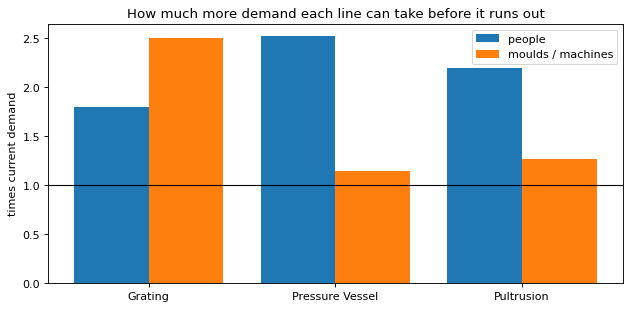

In [27]:
x = np.arange(len(summary))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, summary["people limit (x demand)"], width=0.4, label="people")
ax.bar(x + 0.2, summary["mould/machine limit (x demand)"], width=0.4, label="moulds / machines")
ax.axhline(1, color="black", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_ylabel("times current demand")
ax.set_title("How much more demand each line can take before it runs out")
ax.legend()
plt.tight_layout()
plt.savefig("capacity.png", dpi=110)
plt.show()

## 6. Scenarios

These only change labour (people, overtime, how much of the shift is productive), so they only matter for the line where people are the limit.

Overtime: 4 hours a week per person is about 52 hours a quarter, which is already above the 50 hours a quarter in the Factories Act. The new labour code may have changed this - need to check before using it.

In [28]:
heads = present_days / days_per_month          # average people present on a day
ot_hours = 4 * 4.33 * heads * EFF              # 4 h a week per person

scenarios = pd.DataFrame({
    "base": hours_needed / hours_available,
    "demand +15%": hours_needed * 1.15 / hours_available,
    "2 people fewer per line": hours_needed / ((present_days - 2 * days_per_month) * HOURS_PER_SHIFT * EFF),
    "overtime 4 h/week": hours_needed / (hours_available + ot_hours),
    "effective time 0.75": hours_needed / (hours_available / EFF * 0.75),
    "effective time 0.90": hours_needed / (hours_available / EFF * 0.90),
}).T * 100
scenarios.round(1)

,Grating,Pressure Vessel,Pultrusion
base,55.7,39.7,45.5
demand +15%,64.1,45.7,52.4
2 people fewer per line,77.8,46.8,58.6
overtime 4 h/week,51.3,36.6,41.9
effective time 0.75,62.4,44.5,51.0
effective time 0.90,52.0,37.1,42.5


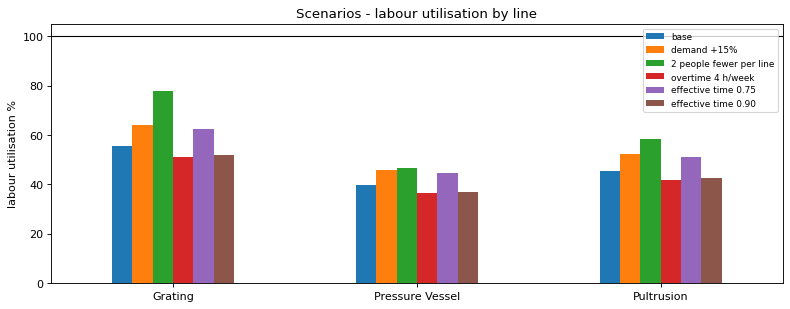

In [29]:
scenarios.T.plot(kind="bar", figsize=(10, 4))
plt.axhline(100, color="black", linewidth=1)
plt.ylabel("labour utilisation %")
plt.title("Scenarios - labour utilisation by line")
plt.xticks(rotation=0)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("scenarios.png", dpi=110)
plt.show()

No line goes over 100% in any scenario. Grating is the highest: 78% if it loses 2 people, 64% with 15% more demand. Pultrusion goes up to 59% and vessels to 47%.

But these scenarios only move labour, and labour isn't what limits vessels and pultrusion - so they look comfortable here when they are not.

## 7. Are the standard hours right?

Everything above uses the Std Hours sheet, which nobody ever time-studied. The Machine Log has the hours the moulds and machines actually ran, so I can compare the two.

The Std Hours note for vessels says "2 man x 8 hr x ~1.6 day" - it assumes **2 people** per mould. But the vessel department has 15 people for 5 moulds, which is **3** per mould.

In [30]:
ml = pd.read_excel("Production_Tracker_RAW.xlsx", sheet_name="Machine Log")
ml["Date"] = ml["Date"].apply(fix_date)
ml["Running Hrs"] = pd.to_numeric(ml["Running Hrs"], errors="coerce")

# vessels - std is man-hours with 2 people, actual is mould hours x 3 people
vessel_out = out[out["Line"] == "Pressure Vessel"]
std_vessel = vessel_out["std_hours"].sum()
actual_vessel = ml.loc[ml["Machine"].str.startswith("VM"), "Running Hrs"].sum() * a["vessel_crew_per_mould"]

# grating - mould log only starts in Jun-25, so compare from then
gr_start = ml.loc[ml["Machine"].str.startswith("GM"), "Date"].min()
grating_out = out[(out["Line"] == "Grating") & (out["Date"] >= gr_start)]
std_grating = grating_out["std_hours"].sum()
actual_grating = ml.loc[ml["Machine"].str.startswith("GM"), "Running Hrs"].sum() * 2

# pultrusion - compare machine hours with machine hours (before the crew conversion)
pult_out = out[out["Line"] == "Pultrusion"]
std_pult = pult_out["std_hours"].sum() / PULT_CREW
actual_pult = ml.loc[ml["Machine"].str.match(r"^M\d$"), "Running Hrs"].sum()

check = pd.DataFrame({
    "std hours": [std_vessel, std_grating, std_pult],
    "actual hours": [actual_vessel, actual_grating, actual_pult],
    "basis": ["man-hours", "man-hours", "machine hours"],
}, index=["Pressure Vessel", "Grating", "Pultrusion"])
check["actual / std"] = (check["actual hours"] / check["std hours"]).round(2)
check.round(0)

,std hours,actual hours,basis,actual / std
Pressure Vessel,13004.0,22994.0,man-hours,2.0
Grating,13685.0,12638.0,man-hours,1.0
Pultrusion,7069.0,15476.0,machine hours,2.0


In [31]:
# vessels again, but in mould hours (take the crew out of both sides)
print("vessel mould hours per vessel - std (2 people):",
      round(std_vessel / 2 / vessels_made, 1),
      " actual:", round(actual_vessel / 3 / vessels_made, 1))

vessel mould hours per vessel - std (2 people): 27.3  actual: 32.2


- **Vessels:** actual man-hours are 1.77x the standard. But in mould hours the gap is only 18% (27.3 vs 32.2 hours per vessel). So most of the difference is the crew - the standard assumes 2 people, the department actually runs 3 per mould.
- **Grating:** actual is 0.92x the standard. Close enough.
- **Pultrusion:** actual machine hours are 2.19x the standard. That is not a crew issue, because both sides are machine hours. Either the standard is wrong or the line runs slower than the sheet assumes - someone needs to time it.

If the actual hours are right, does the answer change?

In [32]:
what_if = summary[["people limit (x demand)", "mould/machine limit (x demand)"]].copy()
what_if["people limit if actual hours"] = (what_if["people limit (x demand)"] / check["actual / std"]).round(2)
what_if["runs out first (std)"] = summary["runs out first"]
what_if["runs out first (actual)"] = np.where(
    what_if["people limit if actual hours"] < what_if["mould/machine limit (x demand)"], "people", "moulds/machines")
what_if

,people limit (x demand),mould/machine limit (x demand),people limit if actual hours,runs out first (std),runs out first (actual)
Grating,1.80,2.50,1.96,people,people
Pressure Vessel,2.52,1.15,1.42,moulds/machines,moulds/machines
Pultrusion,2.20,1.27,1.00,moulds/machines,people


Vessels and grating give the same answer either way. Pultrusion changes: on the standard hours it runs out of machines first, but on the actual hours the people are already at their limit (1.0x) - no labour headroom at all. So the Std Hours sheet has to be fixed before deciding whether pultrusion needs people or machines.

## 8. Checks

In [33]:
mlog = ml[["Running Hrs", "Idle Hrs"]].apply(pd.to_numeric, errors="coerce")
jobs = pd.read_excel("Production_Tracker_RAW.xlsx", sheet_name="Job List")

checks = {
    "no month total rows left": prod["Line"].notna().all(),
    "every date read": prod["Date"].notna().all(),
    "every item matched to a code": prod["Item"].notna().all(),
    "only 3 lines": prod["Line"].nunique() == 3,
    "qty above 0 on every output row": (out["Qty"] > 0).all(),
    "present never more than planned": (mp["Present"] <= mp["Planned"]).all(),
    "present + absent = planned": ((mp["Present"] + mp["Absent"]) == mp["Planned"]).all(),
    "absence within 3 points of the 11% benchmark": abs(absence - 0.11) < 0.03,
    "machine running + idle hours never above 24": (mlog.sum(axis=1) <= 24.01).all(),
    "job no + line no is unique on the job list": not jobs.duplicated(["Job No", "Line No"]).any(),
    "nobody logged on two moulds/machines in one shift":
        prod[~prod["Operator"].isin(["na", "NA", "-"])].dropna(subset=["Operator"])
        .groupby(["Date", "Shift", "Operator"])["Machine/Mould"].nunique().max() == 1,
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)

PASS - no month total rows left
PASS - every date read
PASS - every item matched to a code
PASS - only 3 lines
PASS - qty above 0 on every output row
PASS - present never more than planned
PASS - present + absent = planned
PASS - absence within 3 points of the 11% benchmark
PASS - machine running + idle hours never above 24
PASS - job no + line no is unique on the job list
PASS - nobody logged on two moulds/machines in one shift


In [34]:
# export for the Power BI dashboard
monthly.to_csv("monthly_order_lines.csv")
out.drop(columns=["is_output"]).to_csv("production_clean.csv", index=False)
summary.to_csv("capacity_summary.csv")
scenarios.round(1).to_csv("scenarios.csv")
check.to_csv("std_vs_actual.csv")
print("saved 5 csv files")

saved 5 csv files


## What I found

1. **Vessels are the tightest line, and the limit is moulds.** At the forecast demand the moulds are about 87% used, so only about 15% more demand fits. Adding people won't help - more moulds, or less time on each mould, would.
2. **Pultrusion is the biggest unknown.** On the standard hours the machines run out first (1.3x). On the actual hours from the machine log, the people are already at their limit. The Std Hours sheet needs fixing before any hiring or machine decision.
3. **Grating has room.** About 56% labour utilisation, and even losing 2 people only takes it to 78%.
4. **The Std Hours sheet is out of date.** Vessel standards assume 2 people per mould when the department runs 3, and pultrusion standards are less than half of what the machines actually take.
5. **Simple forecasting was enough.** The long-run average beat last month's figure on every line. With this little data a fancier model would mostly fit noise.

## Limitations

- The data is masked and the rows are rebuilt, so the numbers describe a model of the plant, not its actual results. The point is the method.
- 29 months of orders is short, and the order book has no trend or season, so a simple average winning was always likely.
- Standard hours are a thumb rule. Section 7 shows they are probably too low for vessels and pultrusion.
- One shift a day is my assumption. With two shifts the people limit roughly doubles.
- Pultruded grating (GR-03) is left out - it is sold under Grating but made on the pultrusion line, and it isn't in the tracker. So the pultrusion load is a bit understated.
- The scenarios only move labour. They don't help a line that is limited by moulds or machines.
- The overtime cap needs checking against the new labour code.